In [2]:
using Plots,Distributions, JLD, DSP, Parameters, Match, SymDict, NumericalIntegration, Random, MAT, Pkg, CSV, DataFrames, XLSX, Pkg, JLD2, Colors, ColorSchemes, JLD2,  Makie, CairoMakie, Optim, Serialization, JuMP, Ipopt, Wandb, PyCall,Logging, GLM, PyPlot

include("creation_model.jl")
include("calculate_rates_with_timebase.jl")
include("filter_input.jl") 
# include("run_sim.jl")
# include("run_sim_optim_constant_inh.jl")
include("conv_spikes.jl") 
# include("firing_rates_max.jl") 


conv_spikes (generic function with 1 method)

## Functions for the control algorithm

In [1]:
function run_sim_optim_constant_inh(MN_list,i,inh_input)
    full_input = commoninput 
    _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input,inh_input, MNs)       
    # _, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input, full_input*factor, MNs)       
    spikes = spikes_from_aps(vs, i, MNs)       
    spike_arr = reshape(spikes, 1, length(spikes))
    vs_arr[i,:] = vs
    return spike_arr, vs_arr
end

# function run_sim_optim_constant_inh()
#     for i in 1:nr_s
#         # temp = filter_input(50,rand(Normal(0, 1),sim_length+2000))  # add some gaussian noise - optional
#         # independantnoise[i,:] = temp[1001:end-1000] * 0.25;
#         full_input[i,:] = commoninput  + independantnoise[i,:]; 
#         vd, vs, _ = ode4(tspan, 0.,0., i, pool_state_params[i], full_input[i,:], inh_input, MNs)      
#         spikes = spikes_from_aps(vs, i, MNs)       
#         spike_arr[i,:] = spikes
#         vs_arr[i,:] = vs
#     end
#     return spike_arr, vs_arr
# end


function conv_spikes_rates(array1,array2)
    window_samples = round(Int, 400 * 10^-3 * 20000) ; # 400 ms * 20 kHz  
    hanning_window = DSP.Windows.hanning(window_samples);
    hanning_window ./= sum(hanning_window);# Normalize the window so it sums to 1 (to maintain the same scale after convolution)

    smoothed_spike_array1 = conv(array1[1,:], hanning_window);# Convolve the spike arrays with the Gaussian window
    smoothed_spike_array2 = conv(array2[1,:], hanning_window);

    # Because convolution extends the length of the array, let's truncate it to the original length
    len = size(array1,2);
    smoothed_spike_array1 = smoothed_spike_array1[1:len];
    smoothed_spike_array2 = smoothed_spike_array2[1:len];
    print("")

return smoothed_spike_array1, smoothed_spike_array2
end
   

conv_spikes_rates (generic function with 1 method)

## Init control algorithm

In [3]:
######################  S-TYPE ##########################
#########################################################
nr_s = 87
# JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/hystprofile_NEW.jld2" γn_new
JLD2.@load "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/VthCa_LAST_gamma07.jld2" VthCa_new


# Radius and soma lengths
rheobase_S = LinRange(3.5,6.5,nr_s) .+ rand(Normal(0.0,0.05),nr_s)  
rs_S = LinRange(38.75,41.25,nr_s)./10000 
ls_S = LinRange(77.5,82.5,nr_s)./10000 
rms_S = LinRange(1.15, 1.05,nr_s).*1000
rd_S = LinRange(20.75,31.25,nr_s)./10000 
ld_S = LinRange(5500.,6800.,nr_s)./10000 
rmd_S = LinRange(14.4,10.70,nr_s).*1000 

#  Maximun conductances for each of the ION channels mS/cm^2 
max_gna = 30.0 
max_gkf_S = ones(nr_s)*4 
max_gks_S =LinRange(16,25,nr_s) 
max_gca_S = LinRange(0.038,0.029,nr_s) 


# Rate constants of the kinetic processes in ms^-1
αm = ones(nr_s)*22.0
βm = ones(nr_s)*13.0

αh_S = ones(nr_s)*0.5
βh_S = ones(nr_s)*4

αn_S = ones(nr_s)*1.5
βn_S = ones(nr_s)*0.1

αq_S = ones(nr_s)*1.5
βq_S = LinRange(0.025,0.038,nr_s) 

αp_D = 0.008
βp_D = LinRange(0.014,0.016,nr_s) 

Vthca_S = VthCa_new
Apeak_S = LinRange(0.103,0.123,nr_s)
tpeak_S = LinRange(110.,100.,nr_s) 
tetanic_S = LinRange(0.393,0.491,nr_s);


#EXCITATORY PROFILE
amplitude=0.4
tr_length=28000
half_triang = div(tr_length, 2)  
flat_line = fill(-0.1, 1000)
up = range(-0.1, amplitude, length = half_triang + 1)  
down = range(amplitude, -0.1, length = tr_length - half_triang + 1)  
tr = vcat(flat_line, up[2:end], down[2:end], flat_line)
sim_length=30000

# at some point delete these things
γa=1.;
γh = ones(nr_s)*0.7#γn_new
IF= LinRange(1.,1.,nr_s);  #factor for the inhibtion

#reversal potentials
EL=0; ENa=120; ECa=140; EK=-10; Ee=70; Ei=-16 

#maximun conductances
Ge=0.6; Gi=0.5 ; 

#initial voltages
Vd0 = 0.; 
Vs0 = 0.;

#refractory period
rp=5.0; 

const step = 0.05;
_int(num) = floor(Int, num);

#Pulse duration [mS]
pd=1; 

ri = 70.  # Ω.cm 3intracellular resistivity
cm = 1.; #membrane capacitance

MN_list=[];
Vth_S = zeros(nr_s); gls_S = zeros(nr_s); gld_S = zeros(nr_s); gc_S = zeros(nr_s); gna_S = zeros(nr_s); gkf_S = zeros(nr_s); gks_S = zeros(nr_s); gca_S = zeros(nr_s); rn_S = zeros(nr_s); cs_S = zeros(nr_s)  ; cd_S = zeros(nr_s)
for i in 1:nr_s 
    ##assuming that the somatic membrane can be modeled as a cylinder and using the defined parameters from the previous section
    gls_S[i] = ((2*π*rs_S[i]*ls_S[i])/rms_S[i])*1e6  # conductance of the soma for the ith neuron (uS)
    gld_S[i] = ((2*π*rd_S[i]*ld_S[i])/rmd_S[i])*1e6  # # conductance of the dendrite for the ith neuron (uS)
    gc_S[i] = ((2/(((ri*ld_S[i])/(π*rd_S[i]^2))+((ri*ls_S[i])/(π*rs_S[i]^2)))))*1e6    # coupling conductance in uS
    rn_S[i] = 1/(gls_S[i]+((gld_S[i]*gc_S[i])/(gld_S[i]+gc_S[i]))) # input resistance of the neuron in MΩ     
    Vth_S[i] = round(rn_S[i]*rheobase_S[i],digits=2)   # in mV
    cs_S[i] = 2*π*ls_S[i]*rs_S[i]*cm*1e3   #inner capacitance of the soma nF
    cd_S[i] = 2*π*ld_S[i]*rd_S[i]*cm*1e3   #nF
    
    #conductances uS:
    gna_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gna*1e3          
    gkf_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gkf_S[i]*1e3     
    gks_S[i] = 2*π*ls_S[i]*rs_S[i]*max_gks_S[i]*1e3     
    gca_S[i] = 2*π*ld_S[i]*rd_S[i]*max_gca_S[i]*1e3     

    S_MN = Dict(:Cs => cs_S[i], :Cd => cd_S[i], :Irh => rheobase_S[i], :gc => gc_S[i], :gNa => gna_S[i], :gKs => gks_S[i], :gKf => gkf_S[i], :gCa => gca_S[i], :gld => gld_S[i], :gls => gls_S[i], :αp => αp_D, :βp => βp_D[i], 
        :αq => αq_S[i], :βq => βq_S[i], :αm => αm[i], :βm => βm[i], :αh => αh_S[i], :βh => βh_S[i], :αn => αn_S[i], :βn => βn_S[i], :Vth => Vth_S[i], :VthCa => Vthca_S[i], :Rn => rn_S[i],
        :Tetanic => tetanic_S[i], :Apeak => Apeak_S[i],:IF => IF[i], :tpeak => tpeak_S[i], :γh=>γh[i] , "type" => "All Type")
 
    MN_list = [MN_list;S_MN];
end
MNs = MN_list;


tspan = 0:0.05:sim_length; #time span of simulation defined by step size and length of simulation // change this to get more or less points in the simulation
m=0.0;h=1.0;n=0.0;q=0.0;p=0.0;m0=0.0;h0=1.0;n0=0.0;q0=0.0;p0=0.0; t0=-1.0; t1=-1.0; SPIKE0=0; SPIKE1=0
pool_state_params = fill((m, h, n, q, p, m0, h0, n0, q0, p0, t0, t1, SPIKE0, SPIKE1), nr_s) 
sim_time = _int(sim_length/0.05)   # because the step size is 0.05ms
spike_arr = zeros((nr_s, sim_time)) #storage
vs_arr = zeros((nr_s, sim_time)); #storage
pt_arr = zeros((nr_s, sim_time)); #storage
mt_arr = zeros((nr_s, sim_time)); #storage
ht_arr = zeros((nr_s, sim_time)); #storage
nt_arr = zeros((nr_s, sim_time)); #storage
qt_arr = zeros((nr_s, sim_time)); #storage

commoninput = tr; #needed for the run_sim() function


full_input = zeros((nr_s, sim_length))
independantnoise = zeros((nr_s, sim_length))
factor= 0.1 #for creating the inhibitory signal
inh_input=fill(factor*amplitude, sim_length);


In [16]:
mn1=1; mn2=80
spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1,inh_input)  
spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2,inh_input)

([0 0 … 0 0], [0.0 -0.0027049742475475117 … -6.196753859994924 -6.196753859994924; 0.0 -0.002700608197705891 … -6.138779280898579 -6.138779280898579; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0])

In [17]:
smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  

v = 20
n = div(size(trajectory2_controlled, 1), v)
new_avg = zeros(n, 2)
for i in 1:n
    start_idx = (i - 1) * v + 1
    end_idx = i * v
    new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
    new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
end

trajectory2_controlled = new_avg;

# Plots.plot(trajectory2_controlled[:,1],trajectory2_controlled[:,1])  # Controlled trajectory from neurons)


30000×2 Matrix{Float64}:
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 ⋮    
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0
 0.0  0.0

In [242]:
# Plots.plot([1:30000],tr_new,grid=false,legend=false,linewidth=6,color= :blue)  # Controlled trajectory from neurons)
# Plots.plot!([1:30000],inh_input,grid=false,legend=false,linewidth=6,color= :orange)  # Controlled trajectory from neurons)

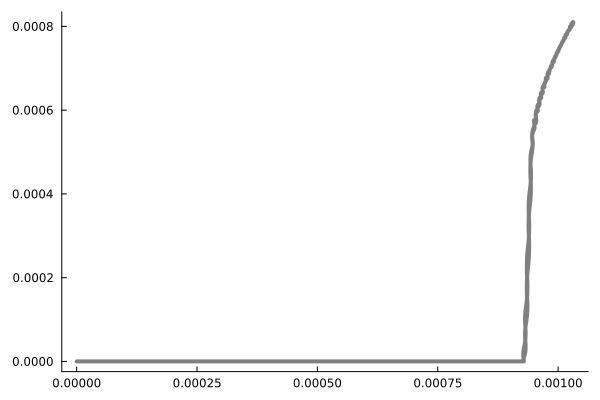

In [18]:
y_values = ones(length(trajectory2_controlled[:, 2]))*maximum(trajectory2_controlled[:, 2]);
x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]));
trajectory1 = hcat(x_values, y_values) ; # This is the line that would make us achieve flexible control;

# Plots.plot(trajectory2_controlled[1:15000,1],trajectory2_controlled[1:15000,2])  # Controlled trajectory from neurons)
# Plots.plot(trajectory2_controlled[15000:30000,1],trajectory2_controlled[15000:30000,2])  # Controlled trajectory from neurons)
Plots.plot(trajectory2_controlled[1:30000,1],trajectory2_controlled[1:30000,2],grid=false,legend=false,linewidth=4,color= :gray)  # Controlled trajectory from neurons)

# Plots.plot!(trajectory1[:,1],trajectory1[:,2])  # Controlled trajectory from neurons)


## Control algorithm

In [198]:
#### NO

# ###################### INH AND EXC ######################
# #########################################################

# # Control parameters
# kp = Float32(4)  
# kd = Float32(0.2)  
# dt = Float32(0.1) 

# # Motoneurons we are interested in comparing
# mn1 = 44
# mn2 = 47

# # Init
# previous_error= 0.0

# tr_new = copy(tr)

# #NOW IT IS THE SAME FOR BOTH
# inh_input1= copy(inh_input)
# inh_input2= copy(inh_input)


# for iteration in 1:200

#     commoninput = tr_new  

#     # Run simulation for the 2 MNs we are comparing
#     spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1, inh_input1) 
#     spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2, inh_input2)  

#     # Convolution of the spikes to get rates for the 2 motoneurons
#     smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
#     trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  # Controlled trajectory from neurons

#     # Compute the average every "v" points
#     v = 20
#     n = div(size(trajectory2_controlled, 1), v)
#     new_avg = zeros(n, 2)
#     for i in 1:n
#         start_idx = (i - 1) * v + 1
#         end_idx = i * v
#         new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
#         new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
#     end

#     trajectory2_controlled = new_avg #avg every 20 points
    

#     # Trajectory we want to achieve (for flexibility)
#     y_values = ones(length(trajectory2_controlled[:, 2]))*maximum(trajectory2_controlled[:, 2])
#     x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
#     trajectory1 = hcat(x_values, y_values)  


#     start= Int(size(trajectory1, 1)/2)

#     for i in start:size(trajectory1, 1) 

#         error1 = trajectory1[i, 1] - trajectory2_controlled[i, 1]
#         error2 = trajectory1[i, 2] - trajectory2_controlled[i, 2]
#         euclidean_error = sqrt(error1^2 + error2^2)
     
#         #ERRORS FROM CONTROL OUTPUT
#         # integral_error += euclidean_error * dt  
#         derivative_error = (euclidean_error - previous_error) / dt
#         control_output = kp * euclidean_error + kd * derivative_error #+ ki * integral_error 
    
#         if tr_new[i] + control_output > 0.35
#             control_output = control_output / 20  # Apply a penalty by reducing the control output
#         end

#         tr_new[i] += control_output  
        
#         inh_input1[i] += control_output
#         inh_input1[i] = clamp(inh_input1[i] , 0, 1)

#         inh_input2[i] -= control_output
#         inh_input2[i] = clamp(inh_input2[i] , 0, 1)

#         previous_error = euclidean_error

#     end

    
# end


In [217]:
###################### EXC ###################### (just controlling exc)
#################################################

# Control parameters
kp = Float32(4)  
kd = Float32(1)  
dt = Float32(0.1) 

# Motoneurons we are interested in comparing
mn1 = 44
mn2 = 47

# Init
previous_error= 0.0

tr_new = copy(tr)

for iteration in 1:20

    commoninput = tr_new  

    # Run simulation for the 2 MNs we are comparing
    spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1, inh_input) 
    spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2, inh_input)  

    # Convolution of the spikes to get rates for the 2 motoneurons
    smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
    trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  # Controlled trajectory from neurons

    # Compute the average every "v" points
    v = 20
    n = div(size(trajectory2_controlled, 1), v)
    new_avg = zeros(n, 2)
    for i in 1:n
        start_idx = (i - 1) * v + 1
        end_idx = i * v
        new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
        new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
    end

    trajectory2_controlled = new_avg #avg every 20 points
    

    # Trajectory we want to achieve (for flexibility)
    y_values = ones(length(trajectory2_controlled[:, 2]))*maximum(trajectory2_controlled[:, 2])
    x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
    trajectory1 = hcat(x_values, y_values)  


    start= Int(size(trajectory1, 1)/2)

    for i in start:size(trajectory1, 1) 

        error1 = trajectory1[i, 1] - trajectory2_controlled[i, 1]
        error2 = trajectory1[i, 2] - trajectory2_controlled[i, 2]
        euclidean_error = sqrt(error1^2 + error2^2)
     
        #ERRORS FROM CONTROL OUTPUT
        # integral_error += euclidean_error * dt  
        derivative_error = (euclidean_error - previous_error) / dt
        control_output = kp * euclidean_error + kd * derivative_error #+ ki * integral_error 
    
        if tr_new[i] + control_output > 0.35
            control_output = control_output / 8  # Apply a penalty by reducing the control output

        end

        tr_new[i] += control_output  

        if tr_new[i]  < 0.145
            tr_new[i]=0.145
        end

        previous_error = euclidean_error

    end

    
end


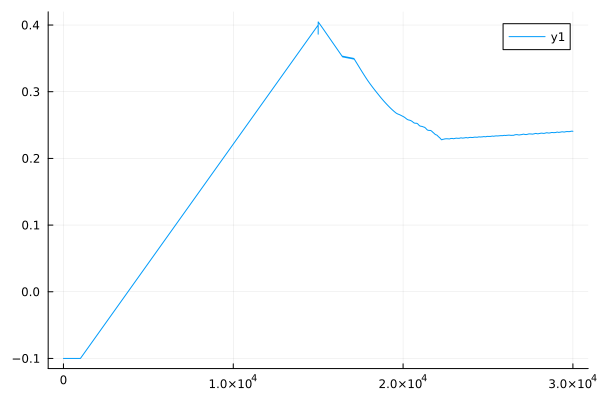

In [240]:
Plots.plot([1:30000],tr_new)

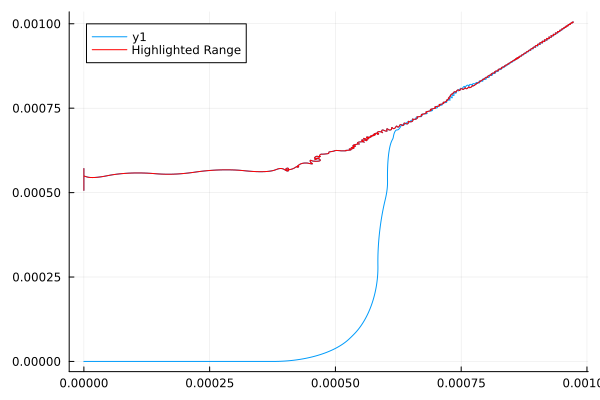

In [231]:

mn1=44; mn2=47
commoninput = tr_new

spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1,inh_input)  
spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2, inh_input)  

##

smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  

v = 20
n = div(size(trajectory2_controlled, 1), v)
new_avg = zeros(n, 2)
for i in 1:n
    start_idx = (i - 1) * v + 1
    end_idx = i * v
    new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
    new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
end

trajectory2_controlled = new_avg;

vals= ones(30000-2000)*maximum(trajectory2_controlled[:, 2]).-0.0004
vals1= LinRange(maximum(trajectory2_controlled[:, 2]),vals[end],2000)

y_values = vcat(vals1, vals)

x1= zeros(2000)
x2= LinRange(0., maximum(trajectory2_controlled[:, 1]),28000)
x_values =  vcat(x1,x2)

trajectory1 = hcat(x_values, y_values)  # This is the line that would make us achieve flexible control


# Highlight the specific range in red

highlight_range = (15000:30000)
highlight_x = trajectory2_controlled[highlight_range,1]
highlight_y = trajectory2_controlled[highlight_range,2]


# Plots.plot(trajectory2_controlled[1:15000,1],trajectory2_controlled[1:15000,2])  # Controlled trajectory from neurons)
# Plots.plot(trajectory2_controlled[15000:30000,1],trajectory2_controlled[15000:30000,2])  # Controlled trajectory from neurons)


Plots.plot(trajectory2_controlled[1:30000,1],trajectory2_controlled[1:30000,2])  # Controlled trajectory from neurons)

# Plots.plot!(trajectory1[:,1],trajectory1[:,2])  # Controlled trajectory from neurons)

Plots.plot!(highlight_x, highlight_y, color=:red, label="Highlighted Range")


In [234]:
# Plots.plot(trajectory2_controlled[1:30000,1],trajectory2_controlled[1:30000,2],grid=false,legend=false,linewidth=4,color= :gray)  # Controlled trajectory from neurons)
# Plots.plot([1:30000],tr_new,grid=false,legend=false,linewidth=4,color= :lightblue)  # Controlled trajectory from neurons)
# Plots.plot!([1:30000],inh_input,grid=false,legend=false,linewidth=4,color= :orange)  # Controlled trajectory from neurons)
# Plots.plot!([1:30000],inh_input2,grid=false,legend=false,linewidth=4,color= :orange,linestyle=:dash)  # Controlled trajectory from neurons)



In [236]:
JLD2.@save "new_exc_flexibility_ONLYEXCchange.jld2" tr_new


## Inputs - excitation and inhibition profiles

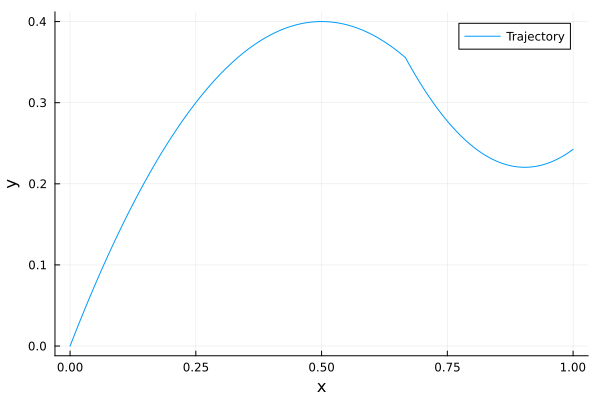

In [160]:
#### parabola for checking what happens

total_length = 30000
max_amplitude = 0.4
half_length = div(total_length, 2)

x1 = range(0, stop=1, length=total_length)[1:20000]
a1 = -max_amplitude * 4
h1 = 0.5
k1 = max_amplitude
y1 = a1 * (x1 .- h1) .^ 2 .+ k1


x2_start = x1[end]
x2 = range(x1[end], stop=1, length=total_length-length(x1))#[1:5000]
a2 = max_amplitude * 6
h2 = 0.904
k2 = y1[end]  # Start at the end point of the first parabola
y2 = a2 * (x2 .- h2) .^ 2 .+ (k2 - a2 * (x2_start - h2)^2)


# y3 = fill(y2[end], 5000)
# x3 = range(x2[end], stop=1, length=total_length-length(x1)-length(x2))

# up = range(y3[end], stop=amplitude, length=2500)
# upx = range(x3[end], stop=1, length=2500)

trajectory = vcat(y1, y2)#,y3)
trajectory_x = vcat(x1, x2)#,x3)


# Plots.plot(x2, y2, label="Trajectory", xlabel="x", ylabel="y")

Plots.plot(trajectory_x, trajectory, label="Trajectory", xlabel="x", ylabel="y")

In [169]:
30000-(h2*30000)

4950.0

In [170]:
inh=fill(0.1*amplitude, sim_length-5400);
down = range(inh[end], stop=0., length=5400)
inh_input1 = vcat(inh,down)
# Plots.plot([1:30000],inh_input,ylim=[0,0.1])

30000-element Vector{Float64}:
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 ⋮
 5.9270235228746075e-5
 5.1861455825152814e-5
 4.445267642155956e-5
 3.70438970179663e-5
 2.9635117614373038e-5
 2.222633821077978e-5
 1.4817558807186519e-5
 7.408779403593259e-6
 0.0

In [172]:
inh=fill(0.1*amplitude, sim_length-5400);
down = range(inh[end], stop=0.2, length=5400)
inh_input2 = vcat(inh,down)
# Plots.plot([1:30000],inh_input,ylim=[0,0.1])

30000-element Vector{Float64}:
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 0.04000000000000001
 ⋮
 0.19976291905908503
 0.1997925541766994
 0.19982218929431378
 0.19985182441192814
 0.19988145952954253
 0.1999110946471569
 0.19994072976477126
 0.19997036488238565
 0.2

## Trial parameters to achieve flexibility

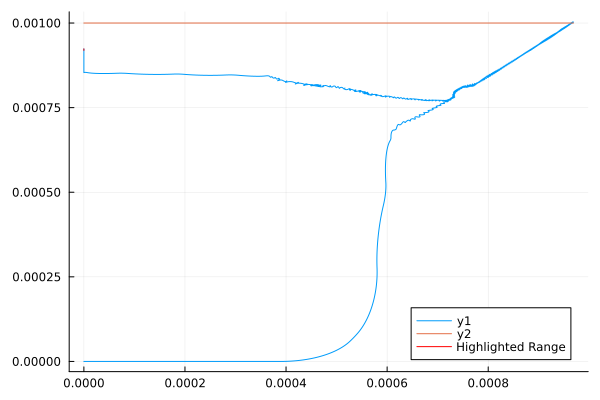

In [167]:
# MN_list[44][:VthCa]=0.
# MN_list[47][:VthCa]=8.

MN_list[47][:γh]=.7
MN_list[47][:γh]=.7

mn1=44; mn2=47
commoninput = trajectory

l= 30000-(h2*30000)

inh=fill(0.1*amplitude, sim_length-5400);
down = range(inh[end], stop=0.4, length=5400)
inh_input = vcat(inh,down)
spike_arr_mn1, _ = run_sim_optim_constant_inh(MN_list[mn1], mn1)  

####

inh=fill(0.1*amplitude, sim_length-5400);
down = range(inh[end], stop=0., length=5400)
inh_input = vcat(inh,down)
spike_arr_mn2, _ = run_sim_optim_constant_inh(MN_list[mn2], mn2)  

##

smoothed_spike_array1, smoothed_spike_array2 = conv_spikes_rates(spike_arr_mn1, spike_arr_mn2)
trajectory2_controlled = hcat(smoothed_spike_array1, smoothed_spike_array2)  

v = 20
n = div(size(trajectory2_controlled, 1), v)
new_avg = zeros(n, 2)
for i in 1:n
    start_idx = (i - 1) * v + 1
    end_idx = i * v
    new_avg[i, 1] = mean(trajectory2_controlled[start_idx:end_idx, 1])
    new_avg[i, 2] = mean(trajectory2_controlled[start_idx:end_idx, 2])
end

trajectory2_controlled = new_avg;


y_values = ones(length(y_values))*0.001
x_values =  range(0., stop=maximum(trajectory2_controlled[:, 1]), length=length(trajectory2_controlled[:, 1]))
trajectory1 = hcat(x_values, y_values)  # This is the line that would make us achieve flexible control


# Highlight the specific range in red

highlight_range = (29900:30000)
highlight_x = trajectory2_controlled[highlight_range,1]
highlight_y = trajectory2_controlled[highlight_range,2]


# Plots.plot(trajectory2_controlled[1:15000,1],trajectory2_controlled[1:15000,2])  # Controlled trajectory from neurons)
# Plots.plot(trajectory2_controlled[15000:30000,1],trajectory2_controlled[15000:30000,2])  # Controlled trajectory from neurons)


Plots.plot(trajectory2_controlled[1:30000,1],trajectory2_controlled[1:30000,2])  # Controlled trajectory from neurons)

Plots.plot!(trajectory1[:,1],trajectory1[:,2])  # Controlled trajectory from neurons)

Plots.plot!(highlight_x, highlight_y, color=:red, label="Highlighted Range")


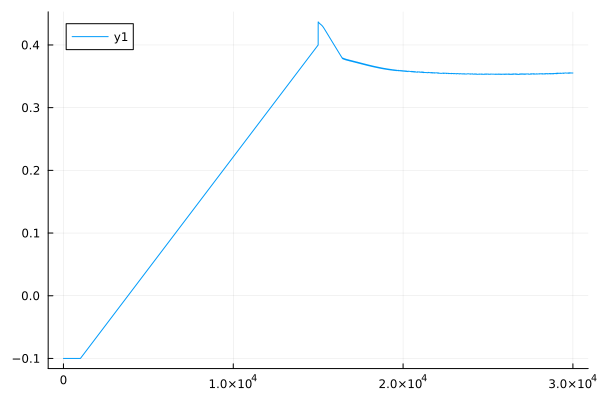

In [41]:
Plots.plot([1:30000],tr_new)